In [3]:
## Path Configuration

import numpy as np
from rastermap import Rastermap, utils
from scipy.stats import zscore

dff_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/dff_trace_20240605fish1spim1.npy'
frames_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/frames.npy'

swims1_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims1.npy'
swims2_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims2.npy'
gain_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/gain.npy'
grating_speed_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/grating_speed.npy'

coordination_data_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/cells0_clean.hdf5'

In [4]:
## Neuron Coordination Computation

import h5py

with h5py.File(coordination_data_path, 'r') as f:
    # print(f.keys())
    cell_x = f['cell_x'][()]
    cell_y = f['cell_y'][()]
    cell_z = f['cell_z'][()]
    
x = np.empty(len(cell_x[:, 0]), dtype=int)
y = np.empty(len(cell_y[:, 0]), dtype=int)
z = np.empty(len(cell_z[:, 0]), dtype=int)

for i in range(len(cell_x[:, 0])):
    x[i] = int(np.round(np.mean(cell_x[i][cell_x[i] != -1])))
    y[i] = int(np.round(np.mean(cell_y[i][cell_y[i] != -1])))
    z[i] = int(np.round(np.mean(cell_z[i][cell_z[i] != -1])))

xyz = []
xyz.append(x)
xyz.append(y)
xyz.append(z)
xyz = np.array(xyz).T
print(xyz)
print(xyz.shape)

[[ 352  203   10]
 [ 294  209   10]
 [ 310  173   10]
 ...
 [ 943  311   16]
 [ 934  317   16]
 [1005  284   16]]
(151066, 3)


In [5]:
# Load Data - Neuron Population
sn = np.load("sn.npy")
sn_T = sn.T
print(sn_T.shape)

# Load Data - Ephs
swims1_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims1.npy'
swims2_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/swims2.npy'
frames_flag = np.load('/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/frames.npy')

swimming_1 = np.load(swims1_path)
swimming_2 = np.load(swims2_path)

segmented_swimming_1 = []
segmented_swimming_2 = []
for i in range(len(sn.T)):
    idx = np.where(frames_flag == i)
    segmented_swimming_1.append(swimming_1[idx])
    segmented_swimming_2.append(swimming_2[idx])



(17122, 3021)


In [6]:
# Load Data - Whole_Brain_Activity
whole_brain_activity = np.load("whole_brain_activity.npy")

In [7]:
# Ephys data process (drop the frame lossed segment)

# framestodrop = np.arange(4309,4331)
frames_flag = np.load(frames_path)
swimming_1 = np.load(swims1_path)
swimming_2 = np.load(swims2_path)
print(frames_flag.shape, swimming_1.shape)

delete_idx = []

for idx in range(len(swimming_1)):
    if 4309 <= frames_flag[idx] < 4331:
        delete_idx.append(idx)
    elif frames_flag[idx] >= 4331:
        frames_flag[idx] = frames_flag[idx] - 22
        
frames_flag = np.delete(frames_flag, delete_idx)
swimming_1 = np.delete(swimming_1, delete_idx)
swimming_2 = np.delete(swimming_2, delete_idx)

print(frames_flag.shape, swimming_1.shape)
print(frames_flag)

(21726380,) (21726380,)
(21698659,) (21698659,)
[    0.     0.     0. ... 17122. 17122. 17122.]


In [8]:
def resample_list(arr_list, target_len=1500):
    results = []
    new_idx = np.linspace(0, 1, target_len)
    for arr in arr_list:
        old_idx = np.linspace(0, 1, len(arr))
        arr_interp = np.interp(new_idx, old_idx, arr)
        results.append(arr_interp)
    return np.array(results)  # shape = (len(arr_list), target_len)


swimming_1_1500 = resample_list(segmented_swimming_1)
swimming_2_1500 = resample_list(segmented_swimming_1)

print(swimming_1_1500)
print(swimming_1_1500.shape)

[[8.23957812e-05 1.26971538e-04 1.57607108e-04 ... 5.07641101e-04
  7.11225800e-04 1.00563379e-03]
 [1.02463000e-03 1.04026963e-03 1.05566411e-03 ... 8.61483963e-04
  8.53491157e-04 8.45042412e-04]
 [8.34311990e-04 8.24787613e-04 8.14899127e-04 ... 2.77866345e-04
  2.77058161e-04 2.76251361e-04]
 ...
 [8.84480291e-05 8.86990913e-05 8.89845675e-05 ... 1.65944378e-04
  1.64913628e-04 1.63829309e-04]
 [1.62467995e-04 1.61267234e-04 1.60023462e-04 ... 1.59982621e-04
  1.60162347e-04 1.60338027e-04]
 [1.60543872e-04 1.60716049e-04 1.60889498e-04 ... 2.30661227e-04
  2.27646574e-04 2.24780547e-04]]
(17122, 1500)


In [9]:
import matplotlib.pyplot as plt

x_min = 0
x_max = 1500 

def rolling_var(x, w):
    mean = np.convolve(x, np.ones(w)/w, mode='same')
    mean_sq = np.convolve(x**2, np.ones(w)/w, mode='same')
    return mean_sq - mean**2

var_series = rolling_var(swimming_1, 9)
# plt.figure(figsize=(10,6))
# plt.plot(var_series[np.where(frames_flag == x_min)[0][0]:np.where(frames_flag == x_max)[0][0]])
# plt.show()

diff_var_series = np.diff(var_series)
# plt.figure(figsize=(10,6))
# plt.plot(diff_var_series[np.where(frames_flag == x_min)[0][0]:np.where(frames_flag == x_max)[0][0]])
# plt.show()

binary_swim1 = (diff_var_series > 4e-9).astype(int)
# plt.figure(figsize=(10,6))
# plt.plot(binary_swim1)
# plt.show()

In [10]:
var_series = rolling_var(swimming_2, 9)
# plt.figure(figsize=(10,6))
# plt.plot(var_series[np.where(frames_flag == x_min)[0][0]:np.where(frames_flag == x_max)[0][0]])
# plt.show()

diff_var_series = np.diff(var_series)
# plt.figure(figsize=(10,6))
# plt.plot(diff_var_series[np.where(frames_flag == x_min)[0][0]:np.where(frames_flag == x_max)[0][0]])
# plt.show()

binary_swim2 = (diff_var_series > 4e-9).astype(int)
# plt.figure(figsize=(10,6))
# plt.plot(binary_swim2)
# plt.show()

In [11]:
def startpoints_of_blocks(binary):
    starts = []
    in_block = False
    start = 0

    for i, val in enumerate(binary):
        if val == 1 and not in_block:
            # 进入一个新 block，记录起点
            start = i
            starts.append(start)
            in_block = True
        elif val == 0 and in_block:
            # 退出 block
            in_block = False

    return np.array(starts)

# 使用方法
startpoints_swim1 = startpoints_of_blocks(binary_swim1) + 4  # convolution window
print(startpoints_swim1.shape)

frame_startpoints_1 = frames_flag[startpoints_swim1]
print(frame_startpoints_1)

startpoints_swim2 = startpoints_of_blocks(binary_swim2) + 4  # convolution window
print(startpoints_swim2.shape)

frame_startpoints_2 = frames_flag[startpoints_swim2]
print(frame_startpoints_2)



# deduplication
def tolerant_unique(arr, tol=5):
    arr = np.asarray(arr)
    result = []
    for x in arr:
        if not any(abs(x - y) <= tol for y in result):
            result.append(x)
    return np.array(result)

# 去重逻辑保持不变
print(tolerant_unique(frame_startpoints_1, tol=10))
print(tolerant_unique(frame_startpoints_2, tol=10))

frame_startpoints = tolerant_unique(np.concatenate([frame_startpoints_1, frame_startpoints_2]), tol=10)
print(frame_startpoints.shape)

(216,)
[  149.   149.   202.   202. 11242. 11242. 11242. 11242. 11242. 11242.
 11243. 11243. 11243. 11243. 11243. 11244. 11244. 11244. 11245. 11245.
 11245. 11245. 11245. 11245. 11245. 11245. 11246. 11246. 11246. 11247.
 11247. 11247. 11329. 11329. 11329. 11329. 11329. 11330. 11330. 11330.
 11330. 11331. 11331. 11331. 11331. 11331. 11332. 11332. 11332. 11333.
 11333. 11333. 11333. 11333. 11333. 11336. 11336. 11336. 11336. 11336.
 11336. 11336. 11341. 11342. 11406. 11406. 11407. 11407. 11407. 11407.
 11407. 11407. 11407. 11407. 11408. 11409. 11409. 11409. 11409. 11409.
 11411. 11411. 11411. 11412. 11412. 11412. 11412. 11412. 11412. 11412.
 11413. 11413. 11413. 11457. 11457. 11457. 11458. 11458. 11458. 11458.
 11458. 11458. 11458. 11458. 11458. 11458. 11458. 11459. 11459. 11459.
 11460. 11460. 11463. 11463. 11464. 11464. 11464. 11464. 11464. 11464.
 11466. 11466. 11466. 11466. 11466. 11614. 11614. 11617. 11617. 11617.
 11618. 11618. 11618. 11618. 11618. 11618. 11618. 11618. 11618. 11618.

In [12]:
print(frame_startpoints)

[  149.   202. 11242. 11329. 11341. 11406. 11457. 11614. 11625. 12204.
 12292. 13466. 13504. 15143. 15576. 16004. 16784. 16802.   857.   925.
  1128.  2108.  2269.  3568.  3735.  3898.  3955.  4239. 11029.]


In [13]:
whole_brain_activity = np.mean(sn, axis=0)
def rolling_var(x, w):
    mean = np.convolve(x, np.ones(w)/w, mode='same')
    mean_sq = np.convolve(x**2, np.ones(w)/w, mode='same')
    return mean_sq - mean**2

var_series = rolling_var(whole_brain_activity, 9)
diff_var_series = np.diff(var_series)
binary = (diff_var_series > 0.013).astype(int)

start_points_Brain = startpoints_of_blocks(binary) + 5
print(start_points_Brain)

[   20   226   317   366   465   534   563   629   670   747   762   815
   843   863   924  1028  1084  1159  1253  1311  1363  1454  1558  1630
  1747  1825  1925  1992  2021  2052  2107  2136  2199  2279  2353  2379
  2452  2528  2560  2610  2640  2676  2787  2930  2976  3123  3292  3387
  3485  3579  3625  3674  3704  3735  3779  3841  3954  4022  4063  4096
  4154  4212  4239  4345  4379  4497  4572  4694  4764  4870  5013  5065
  5142  5219  5304  5373  5485  5542  5588  5671  5721  5849  5970  6041
  6070  6142  6170  6252  6283  6476  6492  6593  6624  6753  6793  6855
  6930  6998  7076  7222  7329  7360  7503  7560  7650  7685  7755  7800
  7955  7986  8103  8238  8341  8377  8405  8520  8557  8566  8601  8765
  8785  8814  9022  9057  9156  9216  9299  9416  9506  9593  9698  9730
  9774  9865  9947 10252 10414 10416 10611 10648 10683 10758 10797 10878
 10921 11029 11091 11142 11182 11241 11251 11328 11338 11343 11406 11415
 11456 11468 11598 11613 11617 11623 12081 12203 12

In [14]:
ephys_location = frame_startpoints
brain_location = start_points_Brain

indices = np.abs(ephys_location[:, None] - brain_location).argmin(axis=1)
nearest = brain_location[indices]

print(nearest)

mask = np.ones(len(brain_location), dtype=bool)
mask[indices] = False
subtracted_brain_location = brain_location[mask]

print(subtracted_brain_location)

[  226   226 11241 11328 11343 11406 11456 11613 11623 12203 12291 13466
 13466 15143 15575 16016 16853 16853   863   924  1159  2107  2279  3579
  3735  3954  3954  4239 11029]
[   20   317   366   465   534   563   629   670   747   762   815   843
  1028  1084  1253  1311  1363  1454  1558  1630  1747  1825  1925  1992
  2021  2052  2136  2199  2353  2379  2452  2528  2560  2610  2640  2676
  2787  2930  2976  3123  3292  3387  3485  3625  3674  3704  3779  3841
  4022  4063  4096  4154  4212  4345  4379  4497  4572  4694  4764  4870
  5013  5065  5142  5219  5304  5373  5485  5542  5588  5671  5721  5849
  5970  6041  6070  6142  6170  6252  6283  6476  6492  6593  6624  6753
  6793  6855  6930  6998  7076  7222  7329  7360  7503  7560  7650  7685
  7755  7800  7955  7986  8103  8238  8341  8377  8405  8520  8557  8566
  8601  8765  8785  8814  9022  9057  9156  9216  9299  9416  9506  9593
  9698  9730  9774  9865  9947 10252 10414 10416 10611 10648 10683 10758
 10797 10878 10921 

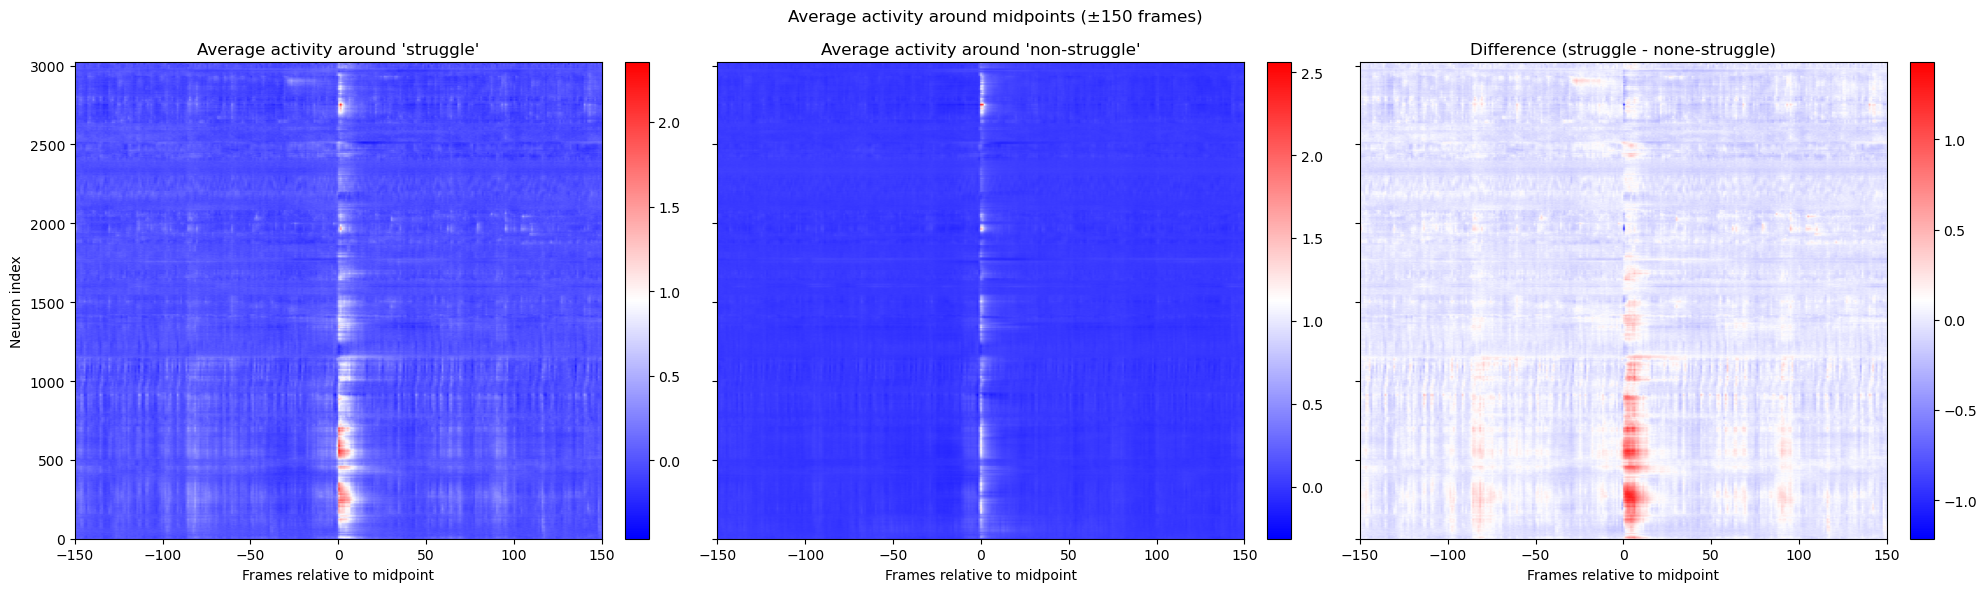

In [15]:
import numpy as np
import matplotlib.pyplot as plt

win = 150  # 正负帧数

def compute_mean_segment(midpoints, sn, win=150):
    """给定 midpoints，计算平均片段 (N, 2*win+1)"""
    segments = []
    for m in midpoints:
        start = m - win
        end = m + win + 1  # 右开区间
        if start >= 0 and end <= sn.shape[1]:  # 保证不越界
            segments.append(sn[:, start:end])
    if len(segments) == 0:
        return None
    segments = np.array(segments)  # shape = (E, N, 2*win+1)
    return segments.mean(axis=0)   # shape = (N, 2*win+1)

# 分别计算 nearest 和 subtracted_brain_location 的平均片段
mean_nearest = compute_mean_segment(nearest, sn, win)
mean_subtracted = compute_mean_segment(subtracted_brain_location, sn, win)

# 绘制三个热图
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

if mean_nearest is not None:
    im1 = axes[0].imshow(mean_nearest, aspect='auto', cmap='bwr',
                         extent=[-win, win, 0, mean_nearest.shape[0]])
    axes[0].set_title("Average activity around 'struggle'")
    axes[0].set_xlabel("Frames relative to midpoint")
    axes[0].set_ylabel("Neuron index")
    plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

if mean_subtracted is not None:
    im2 = axes[1].imshow(mean_subtracted, aspect='auto', cmap='bwr',
                         extent=[-win, win, 0, mean_subtracted.shape[0]])
    axes[1].set_title("Average activity around 'non-struggle'")
    axes[1].set_xlabel("Frames relative to midpoint")
    plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

if (mean_nearest is not None) and (mean_subtracted is not None):
    diff = mean_nearest - mean_subtracted
    im3 = axes[2].imshow(diff, aspect='auto', cmap='bwr',
                         extent=[-win, win, 0, diff.shape[0]])
    axes[2].set_title("Difference (struggle - none-struggle)")
    axes[2].set_xlabel("Frames relative to midpoint")
    plt.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle("Average activity around midpoints (±{} frames)".format(win))
plt.tight_layout()
plt.show()


In [2]:
normalized_dff = zscore(np.load(dff_path), axis=1)

In [17]:
print(normalized_dff.shape)

(151066, 17122)


In [18]:
## crop the normalized_dff
# points = nearest, subtracted_brain_location

struggle_list = []
non_struggle_list = []

window = 10

for i in range(len(nearest)):
    T = nearest[i]
    
    start = T - window
    end = T + window + 1
    
    temp_cropped_neural_signal = normalized_dff[:, start:end]
    struggle_list.append(temp_cropped_neural_signal)
    
for i in range(len(subtracted_brain_location)):
    T = subtracted_brain_location[i]
    
    start = T - window
    end = T + window + 1
    
    temp_cropped_neural_signal = normalized_dff[:, start:end]
    non_struggle_list.append(temp_cropped_neural_signal)

In [20]:
print(len(struggle_list))

29


In [19]:
## concatenate them and calculate the Rastermap
struggle_dff_concatenated = np.concatenate(struggle_list, axis=1)
print(struggle_dff_concatenated.shape)

(151066, 609)


In [21]:
non_struggle_dff_concatenated = np.concatenate(non_struggle_list, axis=1)

In [23]:
print(struggle_dff_concatenated.shape, non_struggle_dff_concatenated.shape)

(151066, 609) (151066, 3818)


In [25]:
all_concatenated = np.concatenate([struggle_dff_concatenated, non_struggle_dff_concatenated], axis=1)
print(all_concatenated.shape)

(151066, 4427)


In [26]:
from rastermap import Rastermap, utils

model = Rastermap(n_clusters=100, # number of clusters to compute
                  n_PCs=200, # number of PCs to use
                  locality=0.1, # locality in sorting is low here to get more global sorting (this is a value from 0-1)
                  time_lag_window=5, # use future timepoints to compute correlation
                  grid_upsample=10, # default value, 10 is good for large recordings
                ).fit(all_concatenated)
y = model.embedding # neurons x 1
isort = model.isort

2025-08-19 15:51:08,346 [INFO] normalizing data across axis=1
2025-08-19 15:51:13,527 [INFO] projecting out mean along axis=0
2025-08-19 15:51:16,786 [INFO] data normalized, 8.63sec
2025-08-19 15:51:16,789 [INFO] sorting activity: 151066 valid samples by 4427 timepoints
2025-08-19 15:51:29,974 [INFO] n_PCs = 200 computed, 21.82sec
2025-08-19 15:51:44,887 [INFO] 100 clusters computed, time 36.73sec
2025-08-19 15:51:52,041 [INFO] clusters sorted, time 43.89sec
2025-08-19 15:51:53,242 [INFO] clusters upsampled, time 45.09sec
2025-08-19 15:51:53,780 [INFO] rastermap complete, time 45.62sec


In [28]:
nbin = 50 # number of neurons to bin over 
sn = utils.bin1d(all_concatenated[isort], bin_size=nbin, axis=0) # bin over neuron axis

In [29]:
print('sn_shape:', sn.shape)
print('sn_type:', type(sn))

sn_shape: (3021, 4427)
sn_type: <class 'numpy.ndarray'>


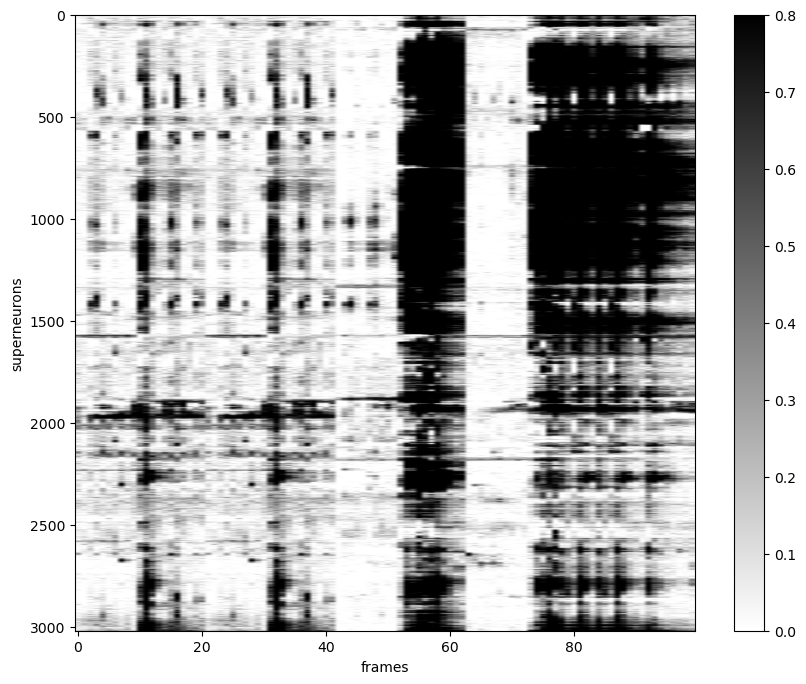

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))   # fig是Figure, ax是Axes
im = ax.imshow(sn[:, 0:100], cmap="gray_r", vmin=0, vmax=0.8, aspect="auto")

ax.set_xlabel("frames")
ax.set_ylabel("superneurons")

plt.colorbar(im, ax=ax)  # 如果需要颜色条
plt.show()

In [33]:
## separate them into list again to draw the heatmap
window_length = 2 * window + 1

total_list_len = len(struggle_list) + len(non_struggle_list)

struggle_sn_list = []
non_struggle_sn_list = []

for i in range(total_list_len):
    start = i * window_length
    end = (i + 1) * window_length
    if (len(struggle_sn_list) < len(struggle_list)):
        struggle_sn_list.append(sn[:,start:end])
    else:
        non_struggle_sn_list.append(sn[:,start:end])

In [39]:
print(len(struggle_sn_list), len(non_struggle_sn_list))
print(struggle_sn_list[1].shape)
print(non_struggle_sn_list[1].shape)

29 182
(3021, 21)
(3021, 21)


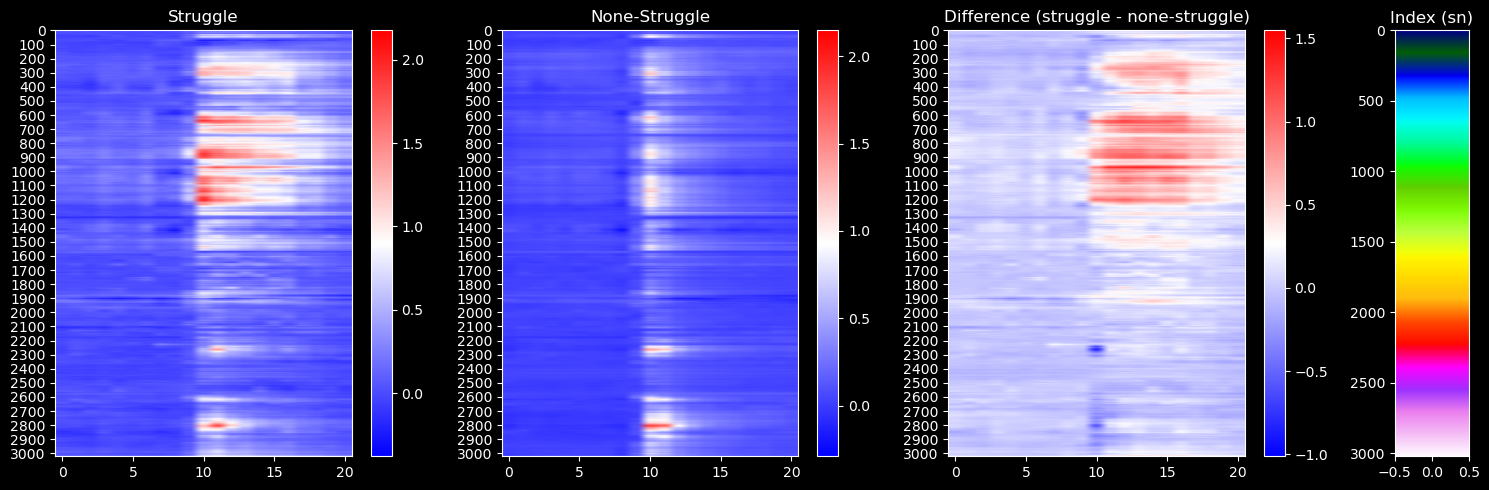

In [99]:
plt.style.use('dark_background')

mean_struggle = np.mean(struggle_sn_list, axis=0)
mean_non_struggle = np.mean(non_struggle_sn_list[:-1], axis=0)

diff = mean_struggle - mean_non_struggle

fig, axes = plt.subplots(1, 4, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1, 1, 0.2]})

im0 = axes[0].imshow(mean_struggle, cmap="bwr", aspect="auto")
axes[0].set_title("Struggle")
nrows = mean_struggle.shape[0]
axes[0].set_yticks(range(0, nrows, 100))
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(mean_non_struggle, cmap="bwr", aspect="auto")
axes[1].set_title("None-Struggle")
axes[1].set_yticks(range(0, nrows, 100))
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(diff, cmap="bwr", aspect="auto")
axes[2].set_title("Difference (struggle - none-struggle)")
axes[2].set_yticks(range(0, nrows, 100))
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(np.arange(0, len(sn))[:, np.newaxis], cmap="gist_ncar", aspect="auto")
axes[3].set_title("Index (sn)")
# plt.colorbar(im3, ax=axes[3])

plt.tight_layout()
plt.show()

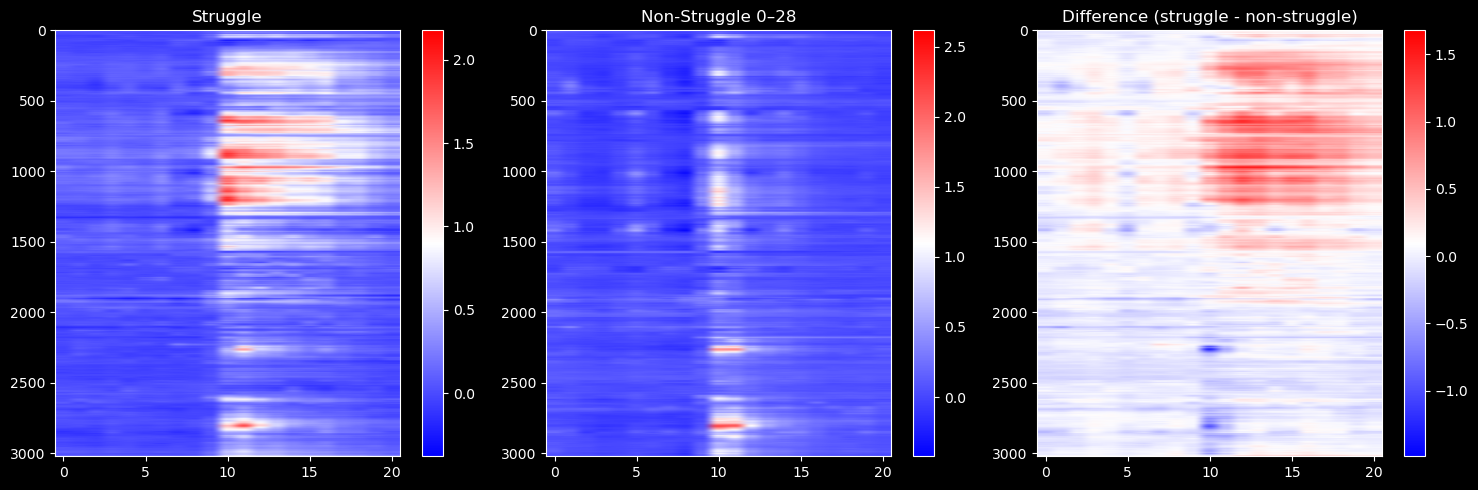

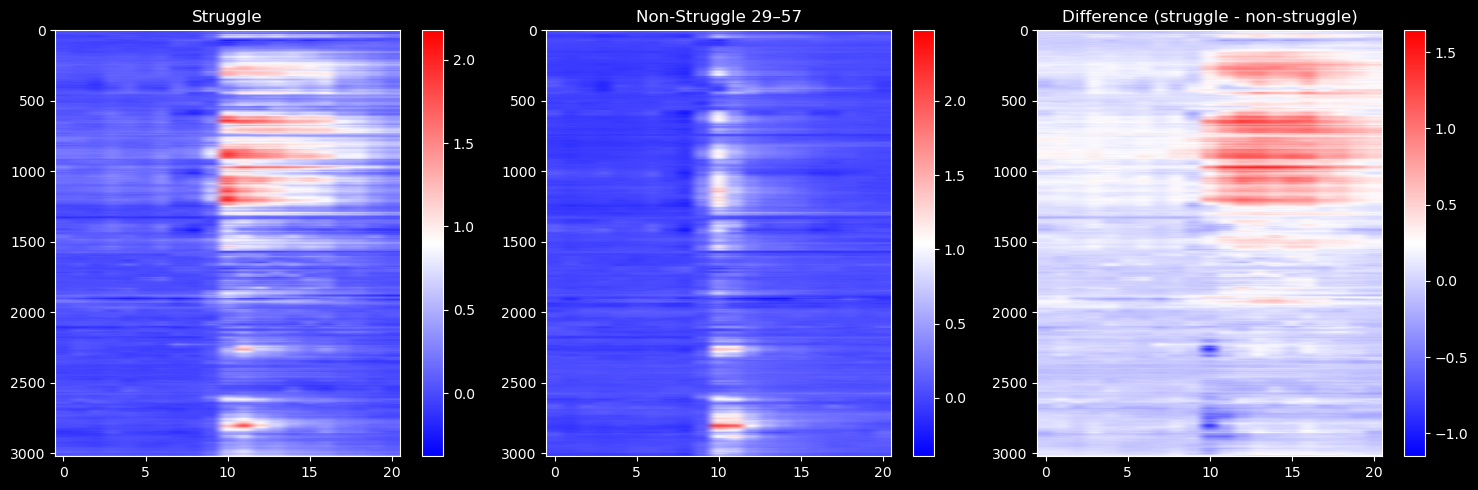

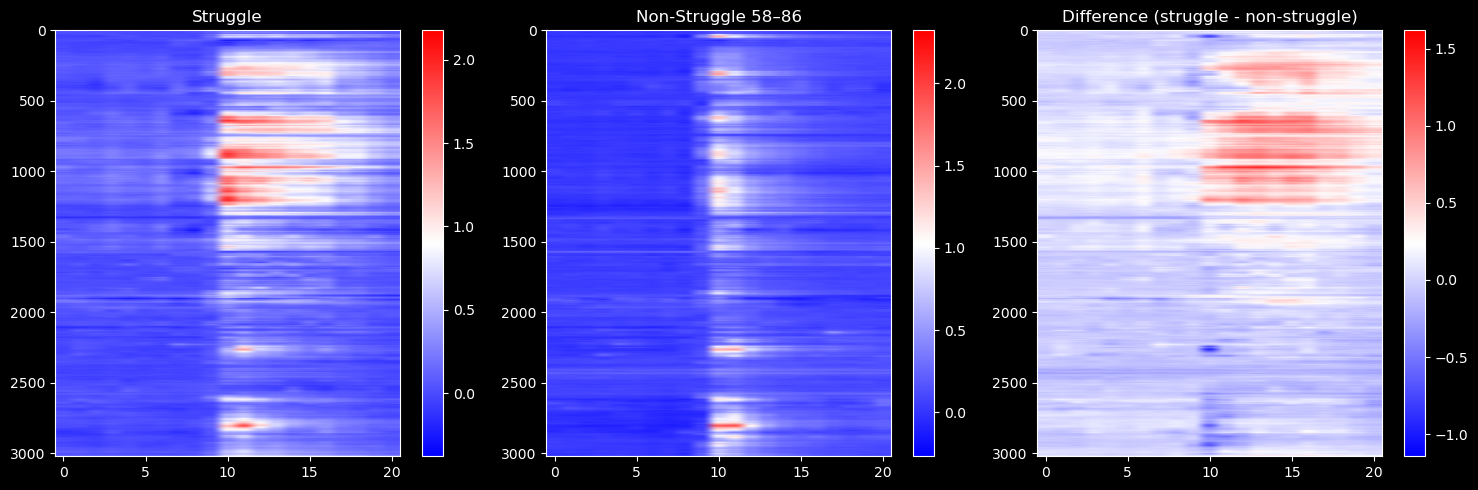

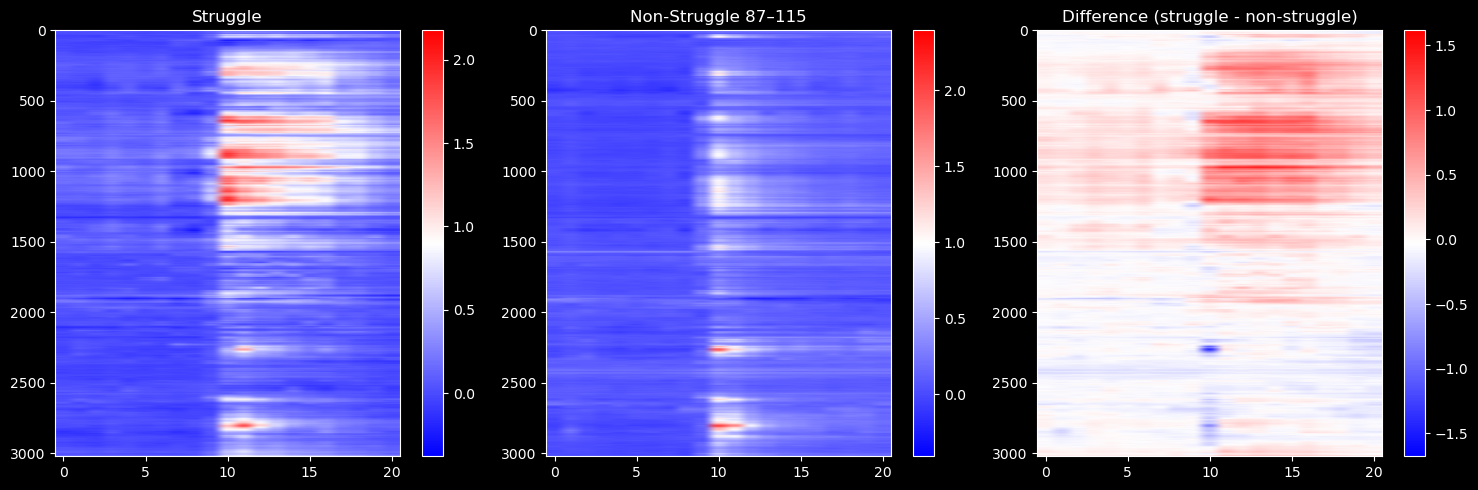

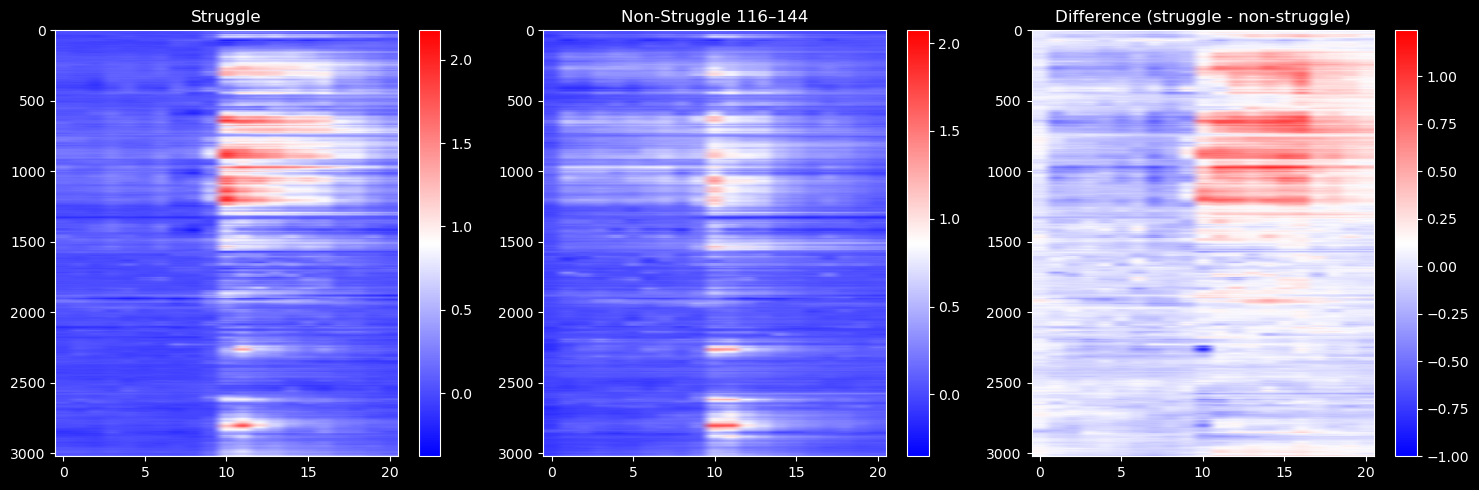

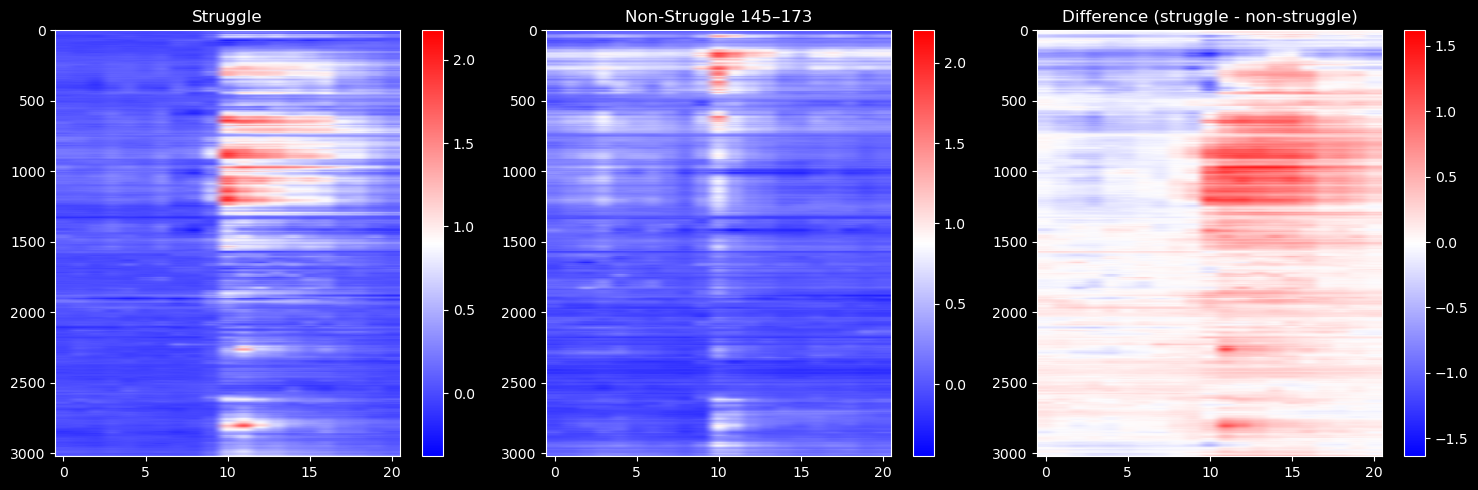

In [46]:
m = len(struggle_sn_list)
n = len(non_struggle_sn_list)

# 逐组取 non_struggle_sn_list 里连续的 m 个
for i in range(0, n - m + 1, m):  # 步长可以改成 1 或 m，看你需求
    # 计算均值
    mean_struggle = np.mean(struggle_sn_list, axis=0)
    mean_non_struggle = np.mean(non_struggle_sn_list[i:i+m], axis=0)

    diff = mean_struggle - mean_non_struggle

    # 画图
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    im0 = axes[0].imshow(mean_struggle, cmap="bwr", aspect="auto")
    axes[0].set_title("Struggle")
    plt.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(mean_non_struggle, cmap="bwr", aspect="auto")
    axes[1].set_title(f"Non-Struggle {i}–{i+m-1}")
    plt.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(diff, cmap="bwr", aspect="auto")
    axes[2].set_title("Difference (struggle - non-struggle)")
    plt.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    plt.show()

In [47]:
coordination_data_path = '/Users/haotianli/Code/EngertLab/Data/image_data/lightsheet_cyto/cells0_clean.hdf5'

with h5py.File(coordination_data_path, 'r') as f:
    # print(f.keys())
    cell_x = f['cell_x'][()]
    cell_y = f['cell_y'][()]
    cell_z = f['cell_z'][()]
    
print(type(cell_x), cell_x.shape)

x = np.empty(len(cell_x[:, 0]), dtype=int)
y = np.empty(len(cell_y[:, 0]), dtype=int)
z = np.empty(len(cell_z[:, 0]), dtype=int)

for i in range(len(cell_x[:, 0])):
    x[i] = int(np.round(np.mean(cell_x[i][cell_x[i] != -1])))
    y[i] = int(np.round(np.mean(cell_y[i][cell_y[i] != -1])))
    z[i] = int(np.round(np.mean(cell_z[i][cell_z[i] != -1])))

xyz = []
xyz.append(x)
xyz.append(y)
xyz.append(z)
xyz = np.array(xyz).T

<class 'numpy.ndarray'> (151066, 107)


In [49]:
a = h5py.File("/Users/haotianli/Desktop/data/DataforHaotian/drive-download-20250625T173846Z-1-002/volume0.hdf5",'r')
brain_map=a['volume_mean'][:,:,:].T
print(brain_map.shape)

(1024, 612, 18)


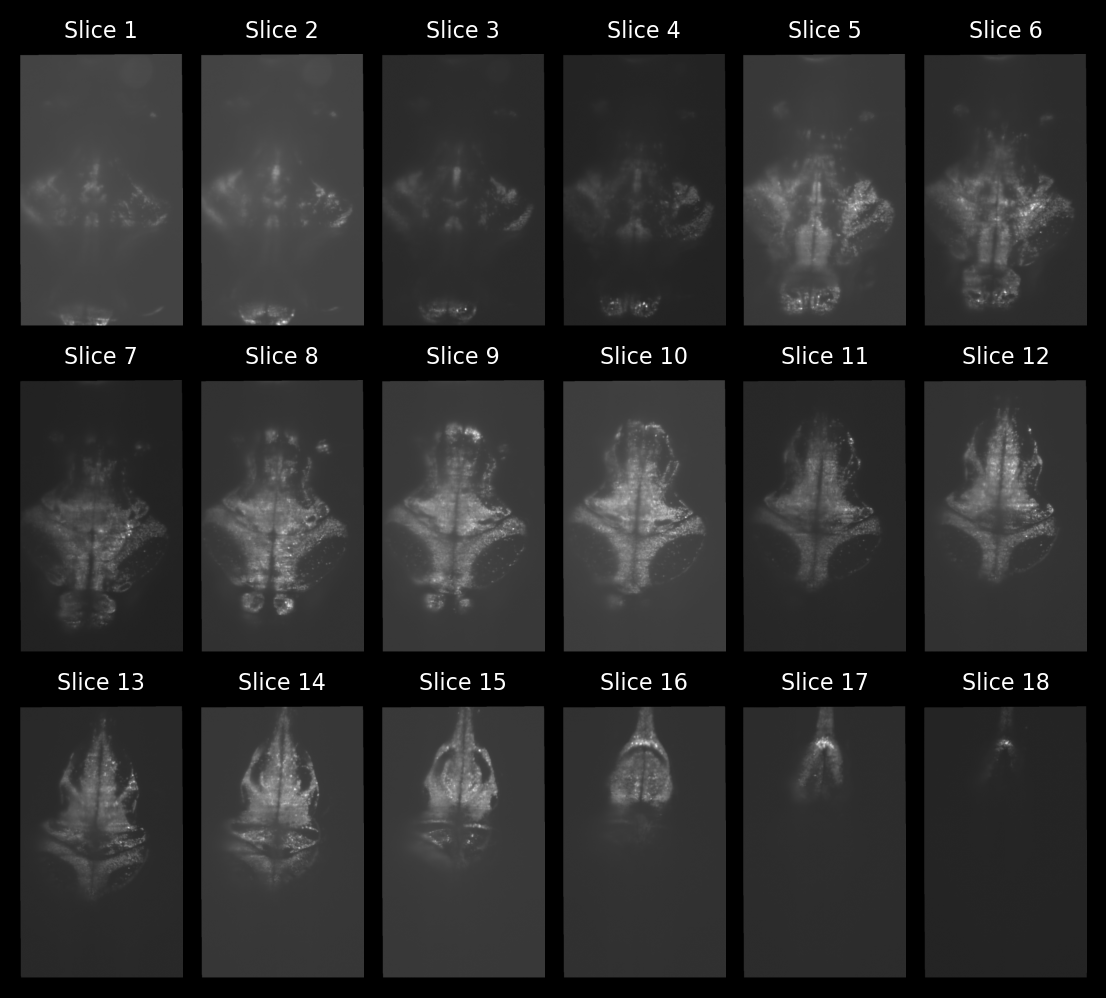

In [68]:
ny, nx = 3, 6  # 3 行 × 6 列
fig, axes = plt.subplots(ny, nx, figsize=(7, 6), dpi=200)

for i in range(18):
    ax = axes[i // nx, i % nx]  # 计算子图位置
    ax.imshow(brain_map[:, :, i], cmap="gray", aspect="auto")
    ax.set_title(f"Slice {i+1}", fontsize=8)
    ax.set_aspect("equal")
    ax.axis("off")

plt.subplots_adjust(wspace=0.0005, hspace=0.2)
# plt.tight_layout()
plt.show()

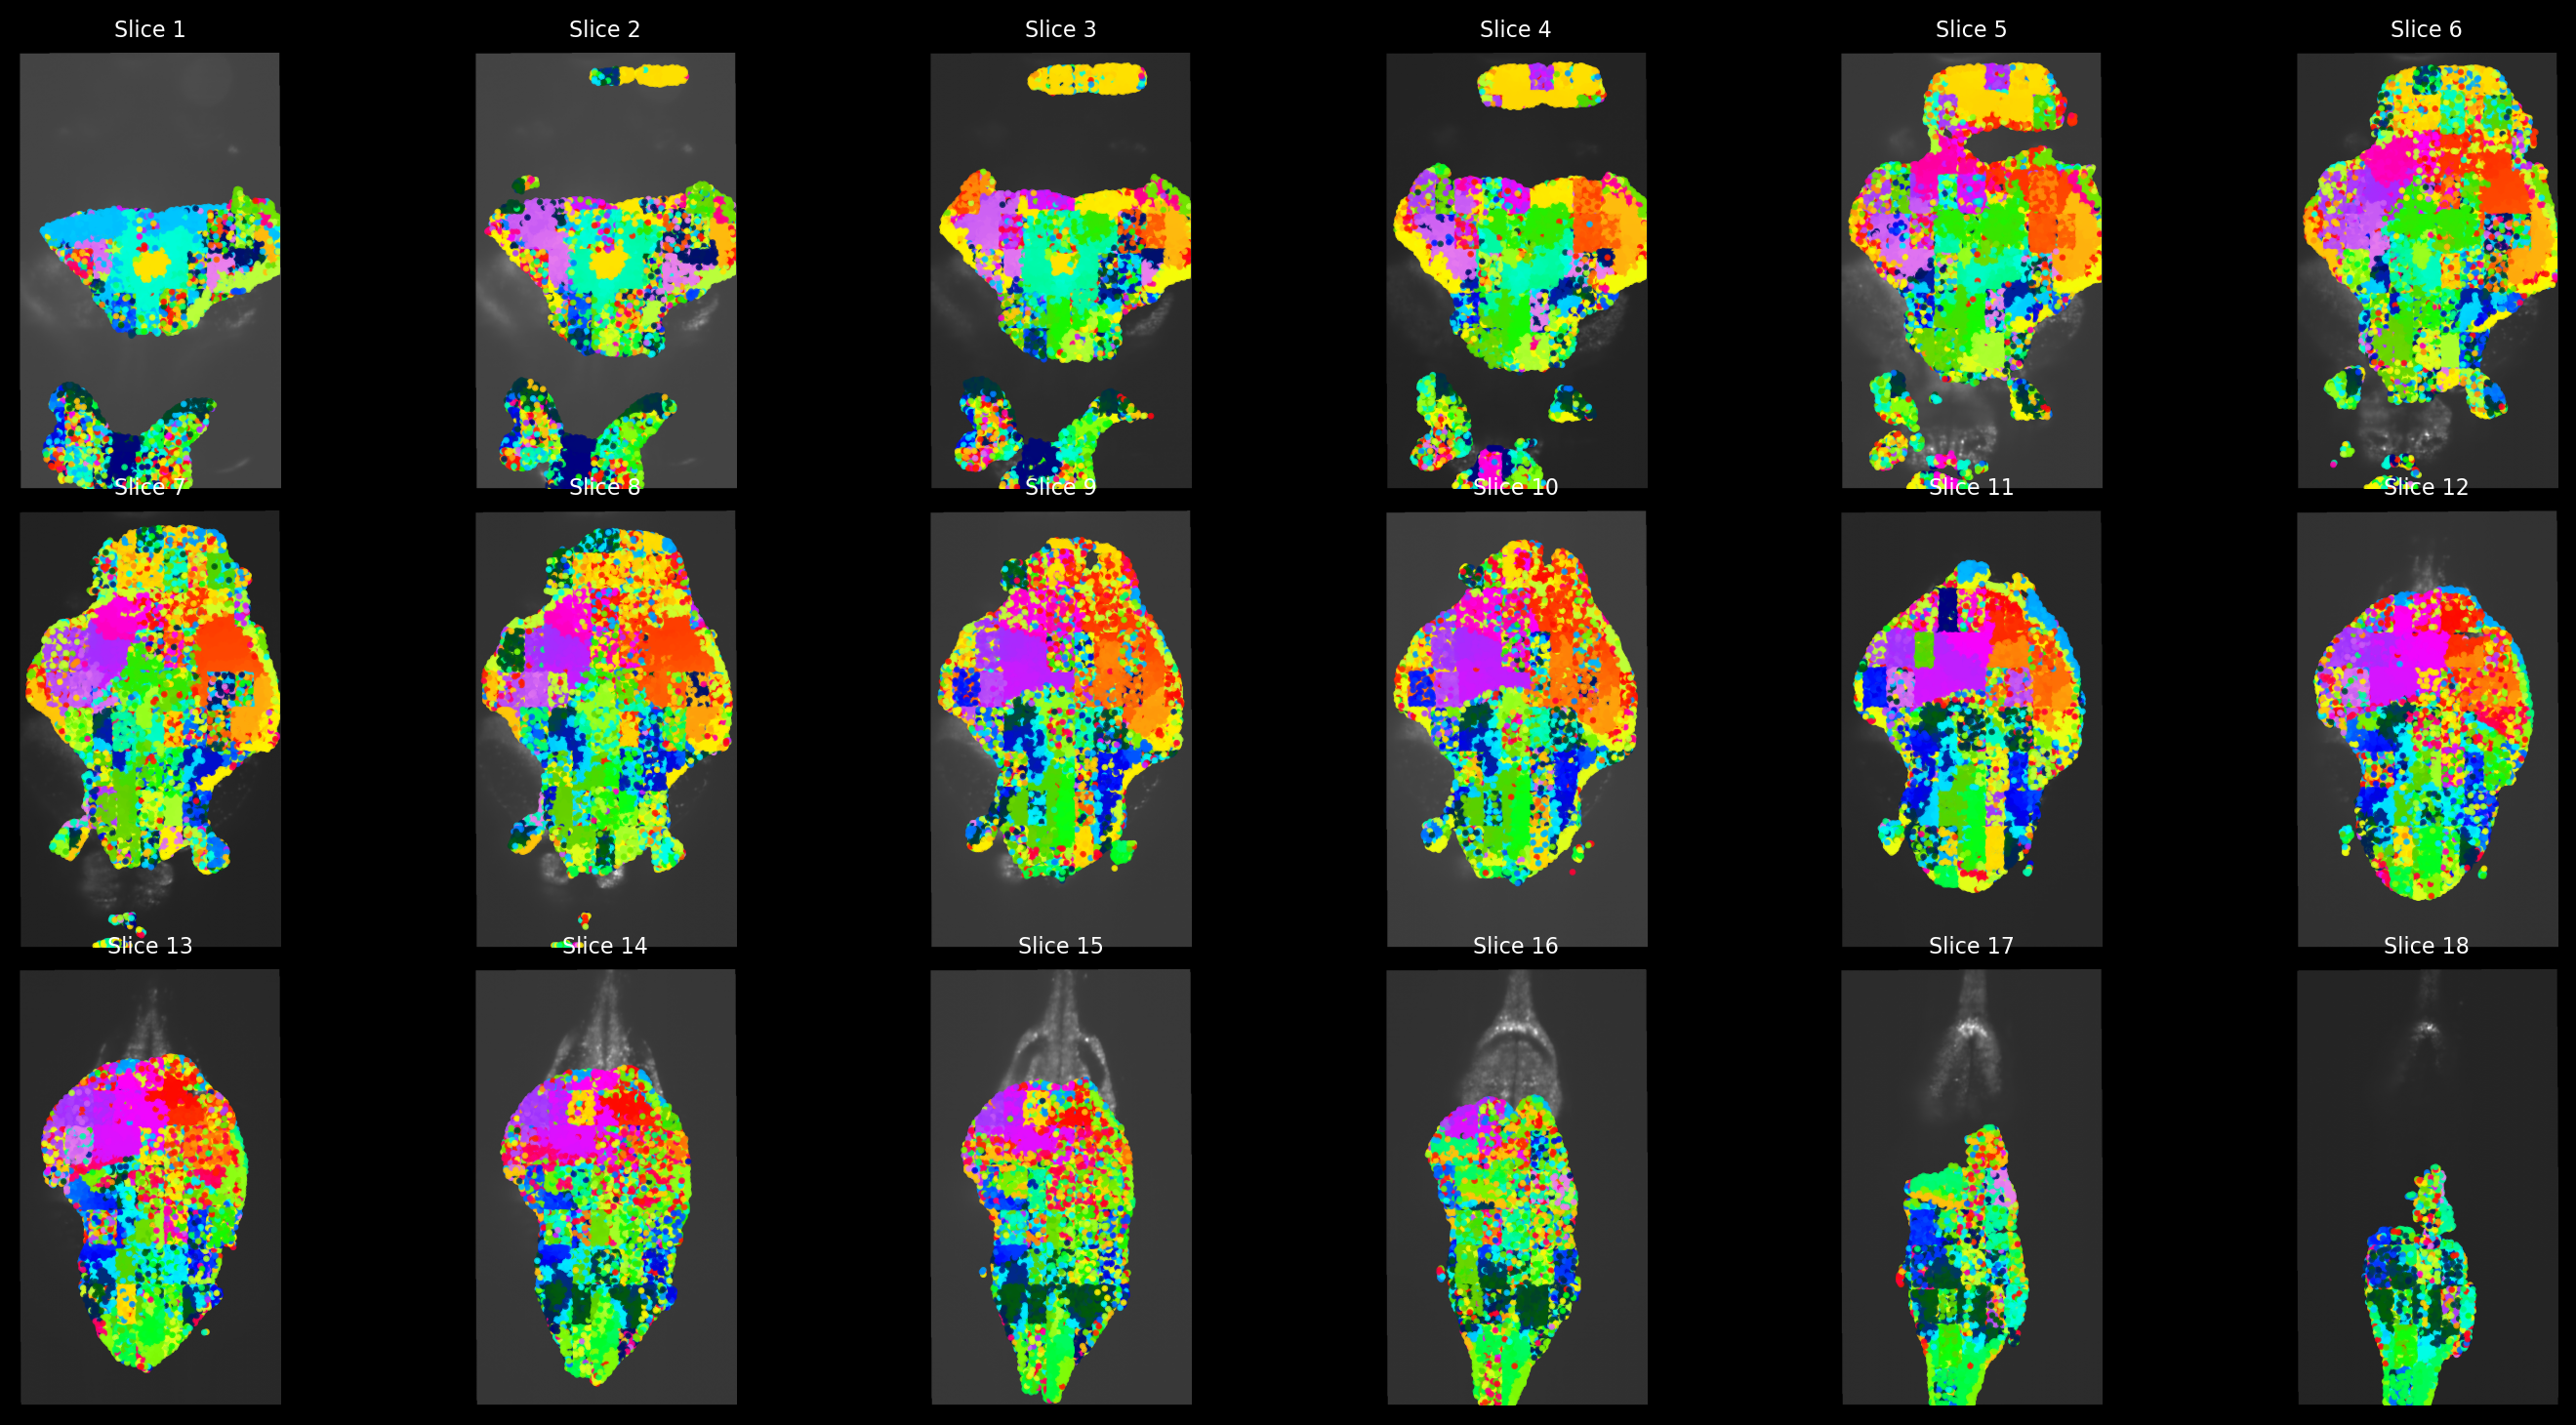

In [70]:
ny, nx = 3, 6
nxy = nx * ny

# 给每个细胞分配颜色 (按照 isort 排序)
cmap = plt.get_cmap("gist_ncar")
colors = cmap(np.linspace(0, 0.9, len(isort)))
cell_colors = np.zeros((len(isort), 4))  # RGBA
cell_colors[isort] = colors  # 排序决定颜色

fig, axes = plt.subplots(ny, nx, figsize=(18, 9), dpi=200)

for i in range(nxy):
    ax = axes[i // nx, i % nx]

    # 1. 背景: z-slice 灰度图
    ax.imshow(brain_map[:, :, i], cmap="gray", aspect="auto")

    # 2. 前景: 筛选出 z 坐标在这一 slice 的细胞
    mask = (xyz[:, 2] == i)   # ⚠️ 如果 z 不是 0~17, 需要离散化
    ax.scatter(
        xyz[mask, 1], xyz[mask, 0],
        s=2, alpha=0.8, color=cell_colors[mask], rasterized=True
    )

    ax.set_title(f"Slice {i+1}", fontsize=8)
    ax.axis("off")
    ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.02, hspace=0.05)
plt.show()

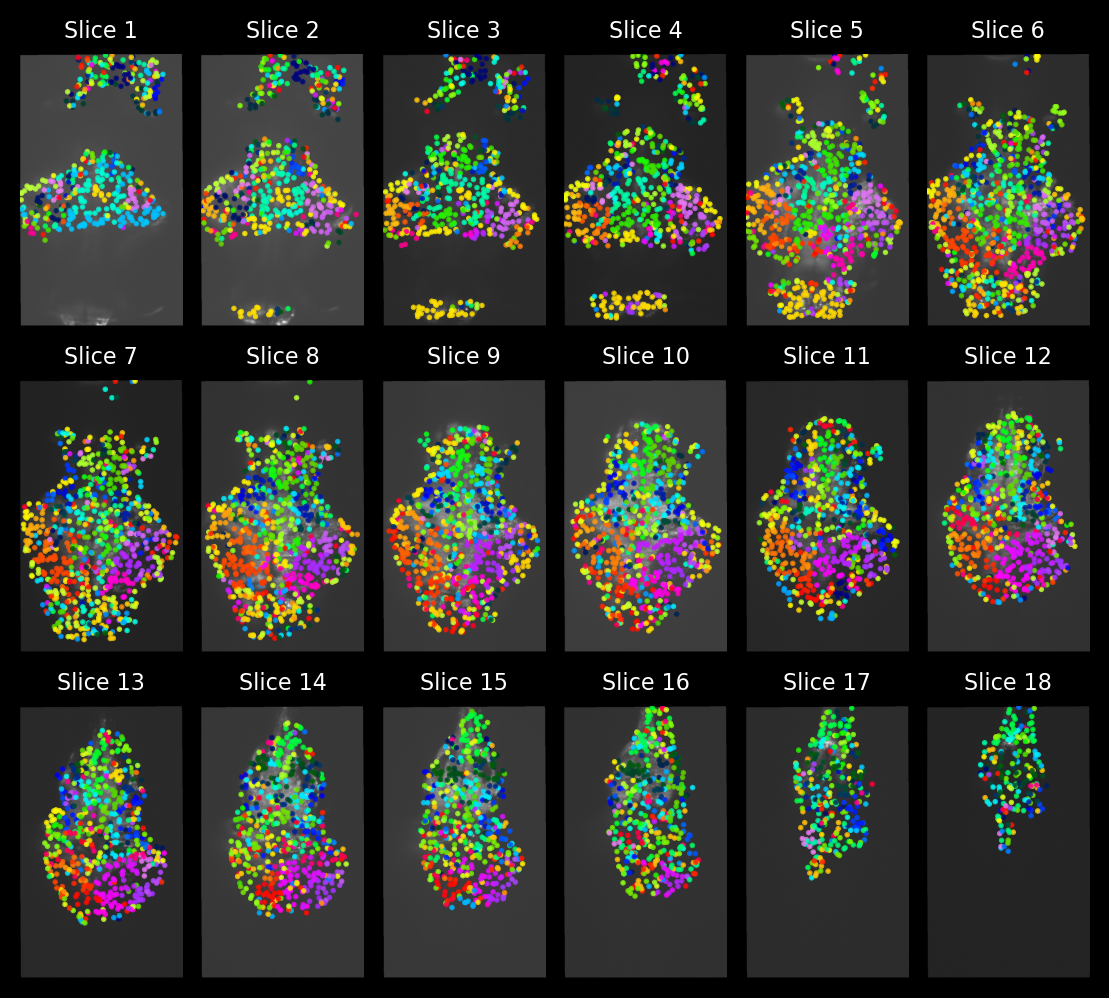

In [96]:
ny, nx = 3, 6
nxy = nx * ny

# 给每个细胞分配颜色 (按照 isort 排序)
cmap = plt.get_cmap("gist_ncar")
colors = cmap(np.linspace(0, 0.9, len(isort)))
cell_colors = np.zeros((len(isort), 4))  # RGBA
cell_colors[isort] = colors  # 排序决定颜色

fig, axes = plt.subplots(ny, nx, figsize=(7, 6), dpi=200)

subsample = 15  # 每 10 个点画一个

for i in range(nxy):
    ax = axes[i // nx, i % nx]

    # 1. 背景: z-slice 灰度图
    ax.imshow(brain_map[:, :, i], cmap="gray", aspect="auto")

    # 2. 前景: 筛选出 z 坐标在这一 slice 的细胞
    mask = (xyz[:, 2] == i)   # ⚠️ 如果 xyz[:,2] 不是 0~17，需要先 bin
    
    W = brain_map.shape[1]
    x_coords = W - 1 - xyz[mask, 1][::subsample]
    # x_coords = xyz[mask, 1][::subsample]
    
    H = brain_map.shape[0]   # 图像的高
    y_coords = H - 1 - xyz[mask, 0][::subsample]
    # y_coords = xyz[mask, 0][::subsample]
    c_coords = cell_colors[mask][::subsample]

    ax.scatter(
        x_coords, y_coords,
        s=1, alpha=0.8, color=c_coords, rasterized=True
    )

    # 3. 格式美化
    ax.set_title(f"Slice {i+1}", fontsize=8)
    ax.axis("off")
    ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.02, hspace=0.2)
plt.show()

In [ ]:
# Specifically Plotting
range_1 = (800*50, 900*50)
range_2 = (2200*50, 2300*50)

ny, nx = 3, 6
nxy = nx * ny

# 给每个细胞分配颜色 (按照 isort 排序)
cmap = plt.get_cmap("gist_ncar")
colors = cmap(np.linspace(0, 0.9, len(isort)))
cell_colors = np.zeros((len(isort), 4))  # RGBA
cell_colors[isort] = colors  # 排序决定颜色

fig, axes = plt.subplots(ny, nx, figsize=(7, 6), dpi=200)

subsample = 10  # 每 10 个点画一个

for i in range(nxy):
    ax = axes[i // nx, i % nx]

    # 1. 背景: z-slice 灰度图
    ax.imshow(brain_map[:, :, i], cmap="gray", aspect="auto")

    # 2. 前景: 筛选出 z 坐标在这一 slice 的细胞
    mask = (xyz[:, 2] == i)   # ⚠️ 如果 xyz[:,2] 不是 0~17，需要先 bin
    
    W = brain_map.shape[1]
    x_coords = W - 1 - xyz[mask, 1][::subsample]
    # x_coords = xyz[mask, 1][::subsample]
    
    H = brain_map.shape[0]   # 图像的高
    y_coords = H - 1 - xyz[mask, 0][::subsample]
    # y_coords = xyz[mask, 0][::subsample]
    c_coords = cell_colors[mask][::subsample]

    ax.scatter(
        x_coords, y_coords,
        s=1, alpha=0.8, color=c_coords, rasterized=True
    )

    # 3. 格式美化
    ax.set_title(f"Slice {i+1}", fontsize=8)
    ax.axis("off")
    ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.02, hspace=0.2)
plt.show()

## Interval Analysis

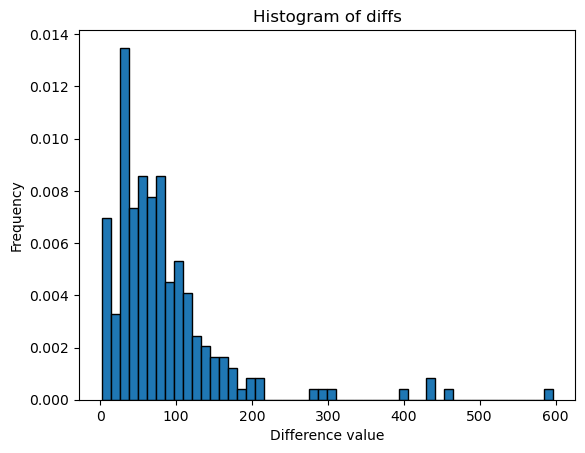

In [21]:
# interval analysis: start_points_Brain
interval_sequence = np.diff(start_points_Brain)

plt.hist(interval_sequence, bins=50, edgecolor="black", density=True)  # density=True 表示画概率分布
plt.xlabel("Difference value")
plt.ylabel("Frequency")
plt.title("Histogram of diffs")
plt.show()